In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
CACHE_DIR = r"C:\ReefSeg\data\raw\hf_cache"
METADATA_DIR = r"C:\ReefSeg\data\raw\metadata"

dataset = load_dataset(
    "josauder/coralscapesV2",
    cache_dir=CACHE_DIR
)

with open(os.path.join(METADATA_DIR, "class_mapping.json"), "r") as f:
    mapping_data = json.load(f)

fine_to_legacy = mapping_data["fine_to_legacy"]

print("Train:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))
print("Test:", len(dataset["test"]))
print("Fine-to-legacy mapping:", len(fine_to_legacy))

Train: 1790
Validation: 170
Test: 473
Fine-to-legacy mapping: 95


In [3]:
def convert_mask(mask):
    mask_array = np.array(mask)
    converted_mask = np.zeros_like(mask_array)

    for fine_id, info in fine_to_legacy.items():
        converted_mask[mask_array == int(fine_id)] = int(info["legacy_id"])

    return converted_mask


sample = dataset["train"][0]
sample_mask = convert_mask(sample["label"])

print("Maske boyutu:", sample_mask.shape)
print("Veri tipi:", sample_mask.dtype)
print("Bulunan sınıf ID'leri:", np.unique(sample_mask))
print("Minimum sınıf ID:", sample_mask.min())
print("Maksimum sınıf ID:", sample_mask.max())

Maske boyutu: (1024, 2048)
Veri tipi: uint8
Bulunan sınıf ID'leri: [ 0  5  6  7  8 13 16 21 23 26 32 36]
Minimum sınıf ID: 0
Maksimum sınıf ID: 36


In [4]:
def preprocess_image(image):
    image_array = np.array(image, dtype=np.float32)

    image_tensor = torch.from_numpy(image_array)
    image_tensor = image_tensor.permute(2, 0, 1)
    image_tensor = image_tensor / 255.0

    return image_tensor


def preprocess_mask(mask):
    mask_array = convert_mask(mask)
    mask_tensor = torch.from_numpy(mask_array.astype(np.int64))

    return mask_tensor

In [5]:
sample = dataset["train"][0]

image_crop = sample["image"].crop((0, 0, 512, 512))
mask_crop = sample["label"].crop((0, 0, 512, 512))

image_tensor = preprocess_image(image_crop)
mask_tensor = preprocess_mask(mask_crop)

print("Image tensor shape:", image_tensor.shape)
print("Image tensor dtype:", image_tensor.dtype)
print("Image min:", image_tensor.min().item())
print("Image max:", image_tensor.max().item())

print("\nMask tensor shape:", mask_tensor.shape)
print("Mask tensor dtype:", mask_tensor.dtype)
print("Mask classes:", torch.unique(mask_tensor))

Image tensor shape: torch.Size([3, 512, 512])
Image tensor dtype: torch.float32
Image min: 0.0
Image max: 1.0

Mask tensor shape: torch.Size([512, 512])
Mask tensor dtype: torch.int64
Mask classes: tensor([ 0,  5,  7, 13, 16, 21, 23, 36])


In [6]:
channel_sum = np.zeros(3, dtype=np.float64)
channel_squared_sum = np.zeros(3, dtype=np.float64)

pixel_count = 0

for index, sample in enumerate(dataset["train"]):
    image_array = np.asarray(sample["image"], dtype=np.float32) / 255.0

    channel_sum += image_array.sum(axis=(0, 1), dtype=np.float64)
    channel_squared_sum += np.square(image_array).sum(axis=(0, 1), dtype=np.float64)

    pixel_count += image_array.shape[0] * image_array.shape[1]

    if (index + 1) % 200 == 0:
        print(f"İşlenen görüntü: {index + 1}/1790")

image_mean = channel_sum / pixel_count

image_std = np.sqrt(
    channel_squared_sum / pixel_count - np.square(image_mean)
)

print("\nRGB Mean:", image_mean)
print("RGB Std:", image_std)

İşlenen görüntü: 200/1790
İşlenen görüntü: 400/1790
İşlenen görüntü: 600/1790
İşlenen görüntü: 800/1790
İşlenen görüntü: 1000/1790
İşlenen görüntü: 1200/1790
İşlenen görüntü: 1400/1790
İşlenen görüntü: 1600/1790

RGB Mean: [0.3155488  0.51109336 0.50385326]
RGB Std: [0.20077191 0.1957371  0.2042009 ]


In [7]:
IMAGE_MEAN = torch.tensor([0.3155488, 0.51109336, 0.50385326]).view(3, 1, 1)
IMAGE_STD = torch.tensor([0.20077191, 0.1957371, 0.2042009]).view(3, 1, 1)


def preprocess_image(image):
    image_array = np.array(image, dtype=np.float32)

    image_tensor = torch.from_numpy(image_array)
    image_tensor = image_tensor.permute(2, 0, 1)
    image_tensor = image_tensor / 255.0

    image_tensor = (image_tensor - IMAGE_MEAN) / IMAGE_STD

    return image_tensor

In [8]:
sample = dataset["train"][0]

image_crop = sample["image"].crop((0, 0, 512, 512))

image_tensor = preprocess_image(image_crop)

print("Shape:", image_tensor.shape)
print("Dtype:", image_tensor.dtype)
print("Minimum:", image_tensor.min().item())
print("Maximum:", image_tensor.max().item())
print("Channel means:", image_tensor.mean(dim=(1, 2)))
print("Channel stds:", image_tensor.std(dim=(1, 2)))

Shape: torch.Size([3, 512, 512])
Dtype: torch.float32
Minimum: -1.9873274564743042
Maximum: 3.3895657062530518
Channel means: tensor([-0.4360, -0.4115, -0.3916])
Channel stds: tensor([0.8477, 0.9295, 0.7711])


In [ ]:
class ReefSegDataset(Dataset):
    def __init__(self, hf_split, crop_size=512):
        self.hf_split = hf_split
        self.crop_size = crop_size
#on-the-fly processing
        image_width, image_height = hf_split[0]["image"].size

        self.crops_per_row = image_width // crop_size #4
        self.crops_per_column = image_height // crop_size #2
        self.crops_per_image = self.crops_per_row * self.crops_per_column

    def __len__(self):
        return len(self.hf_split) * self.crops_per_image

    def __getitem__(self, idx):
        image_index = idx // self.crops_per_image
        crop_index = idx % self.crops_per_image

        row = crop_index // self.crops_per_row
        col = crop_index % self.crops_per_row

        left = col * self.crop_size
        top = row * self.crop_size

        sample = self.hf_split[image_index]

        image_crop = sample["image"].crop((
            left, top,
            left + self.crop_size,
            top + self.crop_size
        ))

        mask_crop = sample["label"].crop((
            left, top,
            left + self.crop_size,
            top + self.crop_size
        ))

        image_tensor = preprocess_image(image_crop)
        mask_tensor = preprocess_mask(mask_crop)

        return image_tensor, mask_tensor

In [10]:
train_dataset = ReefSegDataset(dataset["train"])
val_dataset = ReefSegDataset(dataset["validation"])
test_dataset = ReefSegDataset(dataset["test"])

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 14320
Validation samples: 1360
Test samples: 3784


In [11]:
BATCH_SIZE = 2
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 7160
Validation batches: 680
Test batches: 1892


In [12]:
images, masks = next(iter(train_loader))

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)

print("Image range:", images.min().item(), images.max().item())
print("Mask classes:", torch.unique(masks))

Images shape: torch.Size([2, 3, 512, 512])
Masks shape: torch.Size([2, 512, 512])
Image dtype: torch.float32
Mask dtype: torch.int64
Image range: -2.0701801776885986 3.4090983867645264
Mask classes: tensor([ 0,  2,  4,  5,  7, 13, 16, 19, 21, 23, 27, 28, 32, 33, 35])


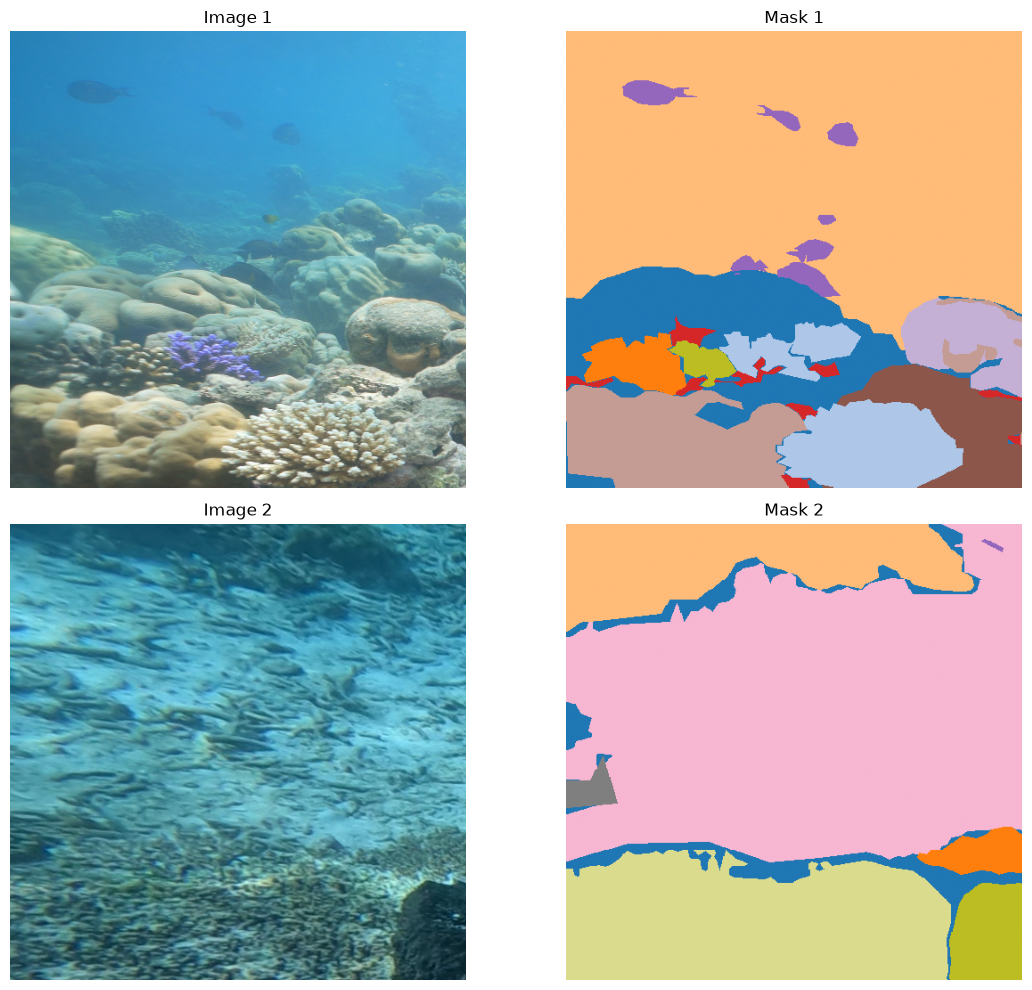

In [13]:
images_denormalized = images * IMAGE_STD + IMAGE_MEAN

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i in range(2):
    image = images_denormalized[i].permute(1, 2, 0).numpy()
    mask = masks[i].numpy()

    axes[i, 0].imshow(np.clip(image, 0, 1))
    axes[i, 0].set_title(f"Image {i + 1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="tab20", vmin=0, vmax=39)
    axes[i, 1].set_title(f"Mask {i + 1}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()